# 04. Tinh Chỉnh, Đánh Giá Tập Test & Xuất 4 Mô Hình — Phân Loại Rủi Ro Khoản Vay

- **Đề tài**: Phân loại rủi ro khoản vay
- **Mục tiêu**:
  1. Tinh chỉnh siêu tham số (Hyperparameter Tuning) cho mô hình dẫn đầu **XGBoost** bằng `RandomizedSearchCV`.
  2. Huấn luyện chính thức cả 4 `Pipeline` trên toàn bộ `train.csv` và chấm điểm công bằng lần cuối trên `test.csv`.
  3. Vẽ **4 Confusion Matrix** (lưới 2×2) và **ROC Curve** của cả 4 thuật toán.
  4. Xuất 4 file `models/*.joblib` và `models/metadata.json` để phục vụ **FastAPI**.

---

## Phần 1: Nạp `train.csv`, `test.csv` & Tinh chỉnh XGBoost (`RandomizedSearchCV`)
- Tìm tổ hợp siêu tham số tối ưu nhất cho XGBoost dựa trên `scoring="f1"` (chỉ chạy trên tập Train).

In [1]:
import time
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

train_df = pd.read_csv("../data/processed/train.csv")
test_df = pd.read_csv("../data/processed/test.csv")

X_train, y_train = train_df.drop(columns=["loan_status"]), train_df["loan_status"].astype(int)
X_test, y_test = test_df.drop(columns=["loan_status"]), test_df["loan_status"].astype(int)

numeric_features = [
    "person_age", "person_income", "person_emp_exp", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length", "credit_score",
]
categorical_features = [
    "person_gender", "person_education", "person_home_ownership",
    "loan_intent", "previous_loan_defaults_on_file",
]

def build_preprocessor():
    return ColumnTransformer(transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ])

xgb_pipe = Pipeline([
    ("preprocess", build_preprocessor()),
    ("classifier", XGBClassifier(tree_method="hist", eval_metric="logloss", random_state=42)),
])

param_dist = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [4, 6, 8],
    "classifier__learning_rate": [0.05, 0.08, 0.12],
    "classifier__subsample": [0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.8, 0.9, 1.0],
}

search = RandomizedSearchCV(
    xgb_pipe, param_distributions=param_dist, n_iter=12,
    scoring="f1", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1, random_state=42, verbose=1,
)
search.fit(X_train, y_train)
print("Best CV F1 sau tuning:", round(search.best_score_, 4))
print("Best params:", search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1 sau tuning: 0.8444
Best params: {'classifier__subsample': 0.9, 'classifier__n_estimators': 400, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.12, 'classifier__colsample_bytree': 1.0}


## Phần 2: Huấn luyện 4 Pipeline & Đánh giá cuối cùng trên `test.csv`
- Huấn luyện cả 4 thuật toán (`logistic_regression`, `svm`, `random_forest`, `xgboost` đã tuning) trên toàn bộ `X_train, y_train`.
- Chấm điểm trên `X_test, y_test` và in bảng so sánh đầy đủ (`Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`, `Train_Seconds`).

In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.svm import LinearSVC

best_xgb_params = {k.replace("classifier__", ""): v for k, v in search.best_params_.items()}

final_classifiers = {
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=42),
    "svm": CalibratedClassifierCV(LinearSVC(max_iter=3000, random_state=42), cv=3),
    "random_forest": RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "xgboost": XGBClassifier(**best_xgb_params, tree_method="hist", eval_metric="logloss", random_state=42),
}

trained_pipelines = {}
test_metrics = {}

for key, clf in final_classifiers.items():
    pipe = Pipeline([("preprocess", build_preprocessor()), ("classifier", clf)])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_sec = round(time.perf_counter() - t0, 3)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    trained_pipelines[key] = pipe
    test_metrics[key] = {
        "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
        "precision": round(float(precision_score(y_test, y_pred)), 4),
        "recall": round(float(recall_score(y_test, y_pred)), 4),
        "f1": round(float(f1_score(y_test, y_pred)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, y_prob)), 4),
        "train_seconds": train_sec,
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    }

display(pd.DataFrame(test_metrics).T.drop(columns=["confusion_matrix"]).sort_values("f1", ascending=False))

,accuracy,precision,recall,f1,roc_auc,train_seconds
xgboost,0.9382,0.8915,0.822,0.8554,0.9792,1.086
random_forest,0.9272,0.9001,0.7565,0.8221,0.9732,1.129
svm,0.895,0.7726,0.7475,0.7598,0.9522,0.555
logistic_regression,0.8947,0.7717,0.747,0.7591,0.9523,0.21


## Phần 3: Trực quan hóa — 4 Confusion Matrix & ROC Curve
- Vẽ lưới 2×2 Confusion Matrix cho cả 4 thuật toán để thấy rõ số ca **False Positive** (duyệt nhầm) và **False Negative** (từ chối nhầm).
- Vẽ biểu đồ ROC Curve chồng cả 4 đường lên nhau.

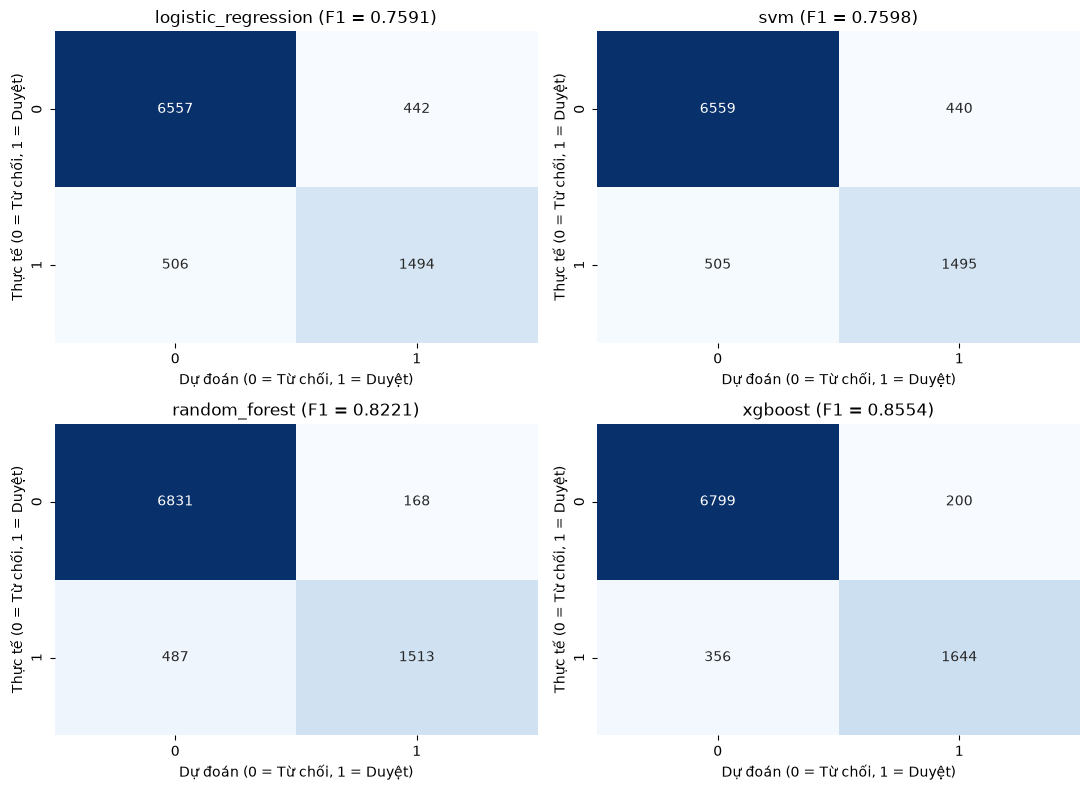

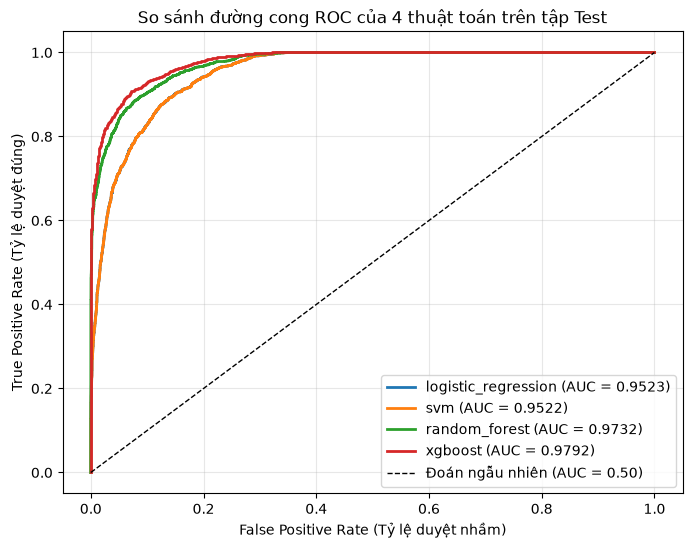

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# 1. Vẽ 4 Confusion Matrix cạnh nhau
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (key, m) in zip(axes.flat, test_metrics.items()):
    sns.heatmap(m["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{key} (F1 = {m['f1']:.4f})")
    ax.set_xlabel("Dự đoán (0 = Từ chối, 1 = Duyệt)")
    ax.set_ylabel("Thực tế (0 = Từ chối, 1 = Duyệt)")
plt.tight_layout()
plt.show()

# 2. Vẽ ROC Curve chồng cả 4 thuật toán
plt.figure(figsize=(8, 6))
for key, pipe in trained_pipelines.items():
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f"{key} (AUC = {test_metrics[key]['roc_auc']:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Đoán ngẫu nhiên (AUC = 0.50)")
plt.xlabel("False Positive Rate (Tỷ lệ duyệt nhầm)")
plt.ylabel("True Positive Rate (Tỷ lệ duyệt đúng)")
plt.title("So sánh đường cong ROC của 4 thuật toán trên tập Test")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

## Phần 4: Xuất 4 file `.joblib`, `models/metadata.json` & Smoke Test
- Lưu 4 Pipeline hoàn chỉnh vào `../models/`.
- Xuất `../models/metadata.json` chứa `best_model`, bảng chỉ số Test, Confusion Matrix và dung lượng file (KB).
- Thử nạp lại `xgboost.joblib` bằng `joblib.load()` và dự đoán 1 hồ sơ thô từ `X_test`.

In [4]:
import json
from pathlib import Path
import joblib

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

for key, pipe in trained_pipelines.items():
    path = models_dir / f"{key}.joblib"
    joblib.dump(pipe, path)
    test_metrics[key]["model_size_kb"] = round(path.stat().st_size / 1024, 1)

best_model_name = max(test_metrics, key=lambda k: test_metrics[k]["f1"])

metadata = {
    "best_model": best_model_name,
    "dataset": "sumit12100012/loan-approval-classification",
    "records_cleaned": len(train_df) + len(test_df),
    "classes": {"0": "Từ chối", "1": "Được duyệt"},
    "features": list(X_train.columns),
    "models": test_metrics,
}

meta_path = models_dir / "metadata.json"
meta_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Đã xuất 4 model và metadata.json! Best model: {best_model_name}")

# Smoke Test: thử nạp lại best model từ đĩa và dự đoán 1 hồ sơ thô
loaded_model = joblib.load(models_dir / f"{best_model_name}.joblib")
sample = X_test.iloc[[0]]
pred = int(loaded_model.predict(sample)[0])
prob = loaded_model.predict_proba(sample)[0]
print(f"Smoke Test -> Dự đoán: {pred} ({metadata['classes'][str(pred)]}) | Xác suất duyệt: {prob[1]*100:.2f}% | Nhãn thật: {y_test.iloc[0]}")

Đã xuất 4 model và metadata.json! Best model: xgboost
Smoke Test -> Dự đoán: 1 (Được duyệt) | Xác suất duyệt: 71.22% | Nhãn thật: 0


## Phần 5: Top 10 Đặc Trưng Quan Trọng Nhất (Feature Importance — XGBoost)
- Nạp trực tiếp `../models/xgboost.joblib` để giải thích mô hình dựa vào những yếu tố nào mạnh nhất khi quyết định duyệt hoặc từ chối khoản vay.

In [ ]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

xgb_pipe = joblib.load("../models/xgboost.joblib")
feature_names = xgb_pipe.named_steps["preprocess"].get_feature_names_out()
importances = xgb_pipe.named_steps["classifier"].feature_importances_

fi_df = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(10)
)
fi_df["feature"] = fi_df["feature"].str.replace("num__", "").str.replace("cat__", "")

plt.figure(figsize=(9, 5))
sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis", hue="feature", legend=False)
plt.title("Top 10 Đặc Trưng Ảnh Hưởng Mạnh Nhất (XGBoost)")
plt.xlabel("Mức độ quan trọng (Feature Importance)")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

display(fi_df.reset_index(drop=True))

## Phần 6: Phân Tích Precision / Recall Theo Ngưỡng Quyết Định (Threshold Tuning)
- Mặc định mô hình dùng ngưỡng `0.50` (`Xác suất >= 50%` → Được duyệt).
- Trong bài toán tín dụng, thay đổi ngưỡng giúp điều chỉnh sự đánh đổi giữa **duyệt nhầm hồ sơ rủi ro (False Positive — giảm Precision)** và **bỏ lỡ khách hàng tốt (False Negative — giảm Recall)**.

In [ ]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

xgb_pipe = joblib.load("../models/xgboost.joblib")
test_df = pd.read_csv("../data/processed/test.csv")
X_test_eval = test_df.drop(columns=["loan_status"])
y_test_eval = test_df["loan_status"].astype(int)

y_prob = xgb_pipe.predict_proba(X_test_eval)[:, 1]
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

rows = []
for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_eval, y_pred_t).ravel()
    rows.append({
        "Ngưỡng": t,
        "Precision": round(precision_score(y_test_eval, y_pred_t), 4),
        "Recall": round(recall_score(y_test_eval, y_pred_t), 4),
        "F1": round(f1_score(y_test_eval, y_pred_t), 4),
        "Duyệt nhầm (FP)": int(fp),
        "Bỏ lỡ khách tốt (FN)": int(fn),
    })

thresh_df = pd.DataFrame(rows)
best_row = thresh_df.loc[thresh_df["F1"].idxmax()]

plt.figure(figsize=(10, 5))
plt.plot(thresh_df["Ngưỡng"], thresh_df["Precision"], marker="o", label="Precision (Ít duyệt nhầm)")
plt.plot(thresh_df["Ngưỡng"], thresh_df["Recall"], marker="s", label="Recall (Ít bỏ lỡ khách tốt)")
plt.plot(thresh_df["Ngưỡng"], thresh_df["F1"], marker="^", linestyle="--", label="F1-Score (Cân bằng)")
plt.axvline(0.50, color="gray", linestyle=":", linewidth=1.5, label="Ngưỡng mặc định (0.50)")
plt.axvline(best_row["Ngưỡng"], color="red", linestyle="-.", linewidth=1.5, label=f"F1 cao nhất ({best_row['Ngưỡng']:.2f})")
plt.title("Đánh Đổi Precision / Recall Theo Ngưỡng Quyết Định (XGBoost)")
plt.xlabel("Ngưỡng xác suất duyệt (Threshold)")
plt.ylabel("Điểm số (Score)")
plt.xticks(thresholds)
plt.ylim(0.5, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

display(thresh_df)